# 01 · Análisis exploratorio de datos

**Objetivo.** Entender qué traen los datos, qué tan confiables son y qué problemas de negocio
pueden resolverse con ellos, antes de construir cualquier modelo.

**Cómo leer este notebook.** Cada sección responde una pregunta y cierra con una
**decisión** (en un recuadro). Las funciones viven en `src/retail_analytics/` y tienen tests;
aquí solo se llaman y se muestran los resultados.

| # | Sección | Pregunta |
|---|---|---|
| 1 | Carga y estructura | ¿Qué hay en cada archivo? |
| 2 | Integridad | ¿Los datos cumplen sus contratos? ¿Falta algo de la malla? |
| 3 | Valores faltantes | ¿Cuántos, dónde y por qué faltan? |
| 4 | Consistencia contable | ¿Los números cuadran entre sí? |
| 5 | Señal de reposición | ¿Cómo se calcula `replenishment_signal`? ¿Se puede usar? |
| 6 | Limpieza | ¿Qué se reconstruye, qué se marca y qué no se toca? |
| 7 | Distribuciones | ¿Cómo se ven las métricas principales? |
| 8 | Patrones temporales | ¿Qué mueve la demanda en el tiempo? |
| 9 | Tiendas | ¿Qué explica que una tienda venda más que otra? |
| 10 | Categorías | ¿Las categorías interactúan entre sí? |
| 11 | Promociones | ¿Venden más los días con promoción? |
| 12 | Picos y extremos | ¿Hay outliers que limpiar? |
| 13 | Conclusiones | ¿Qué decidimos y qué sigue? |

### Resumen de hallazgos

| Hallazgo | Implicación |
|---|---|
| `replenishment_signal` es el promedio de transacciones de **t−5 a t+1**: incluye el día siguiente | No se usa como variable de modelo (fuga de información). Se usa como referencia del sistema actual, en versión corregida |
| En días con promoción, `total_transactions` viene **inflado 8–35%** respecto a efectivo + tarjeta | El conteo válido es `efectivo + tarjeta`; el monto y el ticket lo confirman |
| Los nulos (2–6%) se reparten de forma uniforme; la mayoría se **reconstruye exacto** por identidades contables | Se reconstruye lo deducible; `units_sold` se deja nulo para no filtrar información |
| La demanda la mueven el calendario (fin de semana, quincena, Buen Fin, Navidad) y el nivel de cada tienda | Base del pronóstico |
| El efecto de cada tienda frente a sus pares es **estable en el tiempo** | Base del análisis de potencial |
| Las promociones suben el monto vendido **solo +0.6%**: el descuento se come la venta adicional | Base de la evaluación de promociones |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from retail_analytics import cleaning, quality, viz
from retail_analytics.contracts import TRANSACTIONS_CLEAN, validate_raw
from retail_analytics.io import load_raw, verify_manifest

viz.set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

raw = load_raw()
tx, stores, cal = raw.transactions, raw.stores, raw.calendar

## 1 · Carga y estructura

Tres archivos: transacciones diarias por tienda × categoría, atributos fijos de cada tienda
y un calendario con eventos. La llave del panel es **fecha × tienda × categoría**.

In [2]:
resumen = pd.DataFrame(
    {
        "filas": [len(tx), len(stores), len(cal)],
        "columnas": [tx.shape[1], stores.shape[1], cal.shape[1]],
        "llave": ["date × store_id × category", "store_id", "date"],
    },
    index=["transactions", "stores", "calendar"],
)
resumen

,filas,columnas,llave
transactions,203958,13,date × store_id × category
stores,80,9,store_id
calendar,425,15,date


In [3]:
print(f"Periodo: {tx['date'].min():%Y-%m-%d} a {tx['date'].max():%Y-%m-%d} ({tx['date'].nunique()} días)")
print(f"Tiendas: {tx['store_id'].nunique()} · Categorías: {tx['category'].nunique()}")
tx.head()

Periodo: 2023-01-01 a 2024-02-29 (425 días)
Tiendas: 80 · Categorías: 6


,date,store_id,category,total_transactions,cash_transactions,card_transactions,amount_total,amount_cash,amount_card,units_sold,avg_ticket,has_promotion,replenishment_signal
0,2023-01-01,STR_001,Abarrotes,833,<NA>,326,"244,732.98",NaN,"101,822.79","2,299.00",NaN,0,NaN
1,2023-01-02,STR_001,Abarrotes,1298,750,548,"373,235.09","222,834.25","150,400.84","3,011.00",287.55,0,NaN
2,2023-01-03,STR_001,Abarrotes,1614,931,683,"404,249.92","239,802.59","164,447.33","3,652.00",250.46,0,"1,546.00"
3,2023-01-04,STR_001,Abarrotes,1726,972,754,"423,176.07","246,810.92","176,365.15","4,165.00",245.18,0,"1,699.25"
4,2023-01-05,STR_001,Abarrotes,2159,1028,675,"458,064.93","266,559.26","191,505.67","3,553.00",268.98,1,"1,871.00"


In [4]:
stores.groupby(["store_format", "region"], observed=True).size().unstack(fill_value=0)

region,Centro,Norte,Occidente,Oriente,Sur
store_format,,,,,
Express,3,6,8,4,4
Bodega,7,7,7,10,4
Supercenter,2,4,5,4,5


In [5]:
stores.groupby("store_format", observed=True)[["size_sqm", "num_checkouts"]].agg(["min", "median", "max"])

size_sqm                  num_checkouts           
                  min    median    max           min median max
store_format                                                   
Express           737  1,975.00   2948             4   7.00   9
Bodega           3124  5,442.00   7859            10  14.00  19
Supercenter      8613 11,875.00  14784            20  29.00  37

Los tres formatos están bien separados por tamaño (Express < 3,000 m², Bodega 3,000–8,000,
Supercenter > 8,600) y todos los formatos aparecen en las 5 regiones. Todas las tiendas abrieron
antes de 2023: no hay aperturas dentro del periodo que distorsionen comparaciones.

## 2 · Integridad

Tres chequeos automáticos (los mismos corren en `tests/test_raw_data.py` y en el CI):

1. **Checksum**: los CSV son exactamente los recibidos (versión de datos).
2. **Contratos**: tipos, rangos, llaves únicas y coherencia del calendario (quincena, fin de
   semana y día de la semana derivados de la fecha).
3. **Malla completa**: deberían existir 80 tiendas × 6 categorías × 425 días = 204,000 filas.

In [6]:
print("Checksum:", verify_manifest())
validate_raw(tx, stores, cal)
print("Contratos crudos: OK")

Checksum: {'calendar.csv': True, 'stores.csv': True, 'transactions.csv': True}
Contratos crudos: OK


In [7]:
esperadas = stores.shape[0] * 6 * cal.shape[0]
print(f"Filas esperadas: {esperadas:,} · reales: {len(tx):,} · faltantes: {esperadas - len(tx)}")
quality.grid_gaps(tx, stores, cal)

Filas esperadas: 204,000 · reales: 203,958 · faltantes: 42


,store_id,desde,hasta,dias,filas
0,STR_045,2023-02-01,2023-02-02,2,12
1,STR_055,2024-02-18,2024-02-20,3,18
2,STR_064,2023-02-22,2023-02-23,2,12


> **Decisión.** Faltan solo 42 filas: 3 tiendas con huecos de 2–3 días completos (todas sus
> categorías). El diccionario habla de "periodos completos sin datos"; en la práctica son
> huecos cortos. Se agregan a la malla **marcados** (`is_missing_row`) y **sin rellenar con
> ceros**: no sabemos si la tienda cerró o si falló el envío, y un cero inventaría una caída de
> demanda.

## 3 · Valores faltantes

Antes de decidir qué hacer con los nulos hay que saber **cuántos son, si fallan juntos y si
dependen de algo** (día, tienda, promoción). Si dependen de algo, imputarlos o descartarlos
sesga los resultados.

In [8]:
quality.missing_summary(tx)

,nulos,pct
cash_transactions,12123,5.94
amount_cash,12123,5.94
units_sold,6118,3.00
avg_ticket,4874,2.39
replenishment_signal,960,0.47


In [9]:
cols_nulas = ["cash_transactions", "amount_cash", "units_sold", "avg_ticket", "replenishment_signal"]
quality.null_patterns(tx, cols_nulas)

,cash_transactions,amount_cash,units_sold,avg_ticket,replenishment_signal,filas
0,,,,,,185200
1,x,x,,,,7015
2,,,x,,,5736
3,x,x,,x,,4702
4,,,,,x,866
5,x,x,x,,,198
6,x,x,x,x,,147
7,x,x,,,x,35
8,,,x,,x,33
9,x,x,,x,x,22


- `cash_transactions` y `amount_cash` **siempre faltan juntos**: es una falla del registro de
  efectivo, no de dos campos independientes.
- `units_sold` y `avg_ticket` fallan por separado.
- `replenishment_signal` solo falta en los **dos primeros días del periodo** (se explica en la
  sección 5), no "en los últimos días" como dice el diccionario.

¿Los nulos dependen de algo? Prueba chi-cuadrada de independencia contra día de la semana,
mes, promoción y formato de tienda:

In [10]:
nul = tx.merge(stores[["store_id", "store_format"]], on="store_id").merge(cal[["date", "day_name", "month"]], on="date")
pd.concat(
    [quality.missingness_tests(nul, c, ["day_name", "month", "has_promotion", "store_format"])
     for c in ["cash_transactions", "units_sold", "avg_ticket"]],
    ignore_index=True,
)

,columna,contra,chi2,gl,p_valor,tasa_min_%,tasa_max_%
0,cash_transactions,day_name,7.70,6,0.26,5.70,6.14
1,cash_transactions,month,18.70,11,0.07,5.58,6.38
2,cash_transactions,has_promotion,0.40,1,0.52,5.93,6.01
3,cash_transactions,store_format,7.10,2,0.03,5.74,6.04
4,units_sold,day_name,7.30,6,0.30,2.84,3.15
5,units_sold,month,11.10,11,0.44,2.73,3.15
6,units_sold,has_promotion,0.00,1,0.84,3.00,3.02
7,units_sold,store_format,2.50,2,0.29,2.92,3.08
8,avg_ticket,day_name,2.30,6,0.89,2.30,2.47
9,avg_ticket,month,7.40,11,0.76,2.19,2.54


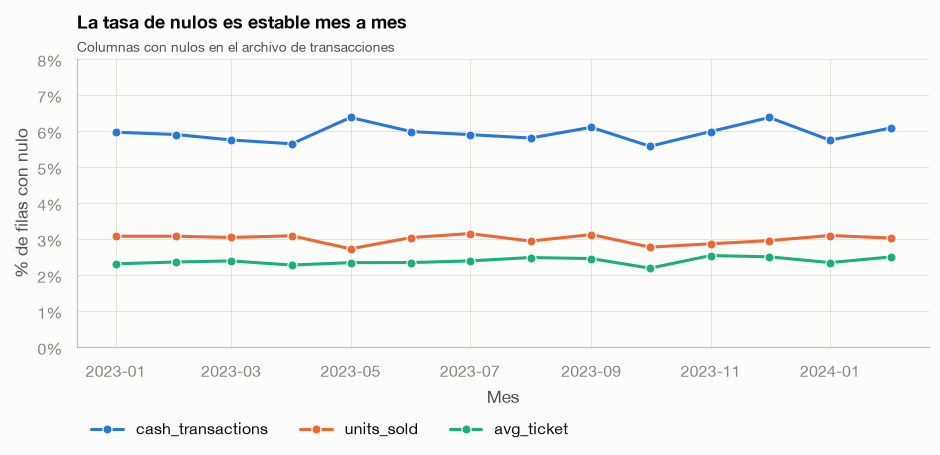

In [11]:
mensual = (
    tx.groupby(tx["date"].dt.to_period("M").dt.to_timestamp())[["cash_transactions", "units_sold", "avg_ticket"]]
    .apply(lambda d: d.isna().mean())
    .reset_index()
    .melt(id_vars="date", var_name="columna", value_name="tasa")
)
fig, ax = plt.subplots(figsize=(10, 3.4))
sns.lineplot(data=mensual, x="date", y="tasa", hue="columna", marker="o", ax=ax)
viz.fmt_pct(ax, decimals=0)
ax.set(ylim=(0, 0.08), xlabel="Mes", ylabel="% de filas con nulo")
ax.set_title("La tasa de nulos es estable mes a mes")
viz.subtitle(ax, "Columnas con nulos en el archivo de transacciones")
ax.legend(title="", ncol=3, loc="upper left", bbox_to_anchor=(0, -0.2))
plt.show()

En 11 de 12 cruces el p-valor es mayor a 0.05 y la tasa de nulos se mueve en un rango estrecho
entre grupos y meses. El único cruce marginal (efectivo contra formato, p = 0.03) es una
diferencia de 0.3 puntos (5.7% vs 6.0%), sin relevancia práctica. **Es consistente con fallas
aleatorias de los puntos de venta** (MCAR).

> **Decisión.** Como los nulos no dependen del día, la tienda ni el mes, descartarlos o
> reconstruirlos no sesga los resultados. Se reconstruye lo que es **deducible** (sección 6) y
> `units_sold` se deja nulo: si hace falta imputarlo, se hará **dentro del pipeline de
> entrenamiento usando solo datos de train**, para no filtrar información del periodo de prueba.

## 4 · Consistencia contable

Como solo hay dos medios de pago, deberían cumplirse estas identidades en cada fila:

- `total_transactions = cash_transactions + card_transactions`
- `amount_total = amount_cash + amount_card`
- `avg_ticket = amount_total / transacciones`

**Cómo se calcula.** En cada fila se calculan los dos lados de cada identidad y se cuentan las
filas donde son iguales (con tolerancia de 1 centavo para montos). Las filas donde falta alguno
de los valores no se cuentan: no son evaluables. Se separan días con y sin promoción:

In [12]:
quality.accounting_identities(tx)

promocion,sin promo (%),con promo (%)
identidad,,
monto = efectivo + tarjeta,100.00,100.00
ticket = monto / (efectivo + tarjeta),100.00,100.00
ticket = monto / total_tx,100.00,0.00
total_tx = efectivo + tarjeta,100.00,0.00


- **Sin promoción todo cuadra al 100%.**
- **Con promoción, `total_transactions` nunca cuadra** con efectivo + tarjeta (0%).
- El **monto sí cuadra siempre**, y el **ticket del sistema está calculado sobre efectivo +
  tarjeta**, no sobre el total.

Es decir, el dinero y el ticket confirman que el conteo real es efectivo + tarjeta: en días de
promoción el total trae **transacciones sin medio de pago** ("fantasma"). Un ejemplo concreto:

In [13]:
cols = ["date", "has_promotion", "total_transactions", "cash_transactions", "card_transactions", "amount_total", "avg_ticket"]
ej = tx[(tx["store_id"] == "STR_001") & (tx["category"] == "Abarrotes") & tx["date"].between("2023-01-18", "2023-01-20")][cols].copy()
ej["efectivo + tarjeta"] = ej["cash_transactions"] + ej["card_transactions"]
ej["monto / (efectivo + tarjeta)"] = ej["amount_total"] / ej["efectivo + tarjeta"]
ej

,date,has_promotion,total_transactions,cash_transactions,card_transactions,amount_total,avg_ticket,efectivo + tarjeta,monto / (efectivo + tarjeta)
17,2023-01-18,0,1142,685,457,"310,230.35",271.66,1142,271.66
18,2023-01-19,0,1267,635,632,"347,308.27",274.12,1267,274.12
19,2023-01-20,1,1974,982,796,"455,548.98",256.21,1778,256.21


In [14]:
fant = quality.phantom_transactions(tx)
inflacion = (tx["total_transactions"] / (tx["cash_transactions"] + tx["card_transactions"]) - 1)[tx["has_promotion"] == 1]
print(f"Transacciones fantasma en el periodo: {fant.sum():,.0f} ({fant.sum() / (tx['total_transactions'].sum() - fant.sum()):.1%} sobre el conteo real)")
print(f"Inflación en días con promoción: mediana {inflacion.median():.1%}, rango {inflacion.min():.1%} a {inflacion.max():.1%}")

Transacciones fantasma en el periodo: 5,021,903 (4.2% sobre el conteo real)
Inflación en días con promoción: mediana 22.2%, rango 8.3% a 35.0%


> **Decisión.** El conteo válido de transacciones es `transactions_clean = efectivo + tarjeta`.
> `total_transactions` se conserva solo para trazabilidad y queda **prohibida como variable**
> (`configs/config.yaml → leaky_columns`).
>
> **Por qué importa para el negocio:** quien mida las promociones con `total_transactions` verá
> un incremento que no existe (sección 11). En la operación real habría que validar con el
> equipo de punto de venta; una causa típica es registrar la aplicación de un cupón como una
> transacción aparte.

## 5 · Señal de reposición

Según el diccionario, `replenishment_signal` se "calcula internamente con base en la demanda
observada". Para saber si se puede usar hay que saber **con qué datos se calcula**. 

**Cómo se calcula.** Para cada tienda-categoría se construyen cuatro promedios móviles de 7 días
de `total_transactions`, cada uno terminando en un día distinto respecto a la fecha `t` de la
fila (t−1, t, t+1, t+2). Luego se compara cada promedio contra la señal, fila por fila: si la
diferencia es menor a 0.01, cuenta como coincidencia exacta.

In [15]:
quality.replenishment_window_check(tx)

,ventana,termina_en,coincidencia_exacta_%,error_abs_mediano
0,t-7 … t-1,-1,0.30,16.71
1,t-6 … t,0,0.49,10.86
2,t-5 … t+1,1,100.00,0.00
3,t-4 … t+2,2,0.49,10.86


La señal coincide **exacto en el 100% de las filas con señal** con el promedio de
`total_transactions` de **t−5 a t+1**. **Incluye el dato del día siguiente**, que no existe al
momento de calcularla. Las otras ventanas no coinciden en más del 0.5% de las filas.

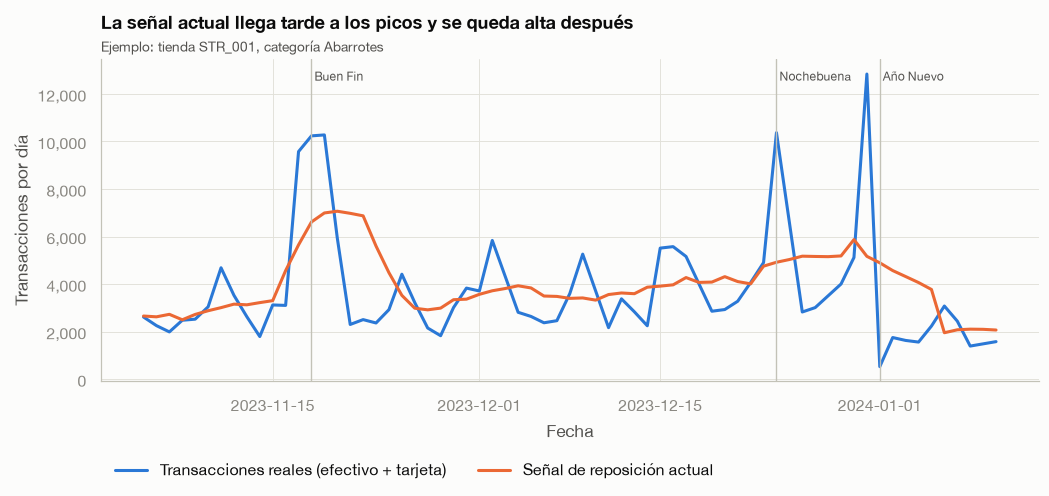

In [16]:
s = tx[(tx["store_id"] == "STR_001") & (tx["category"] == "Abarrotes")].set_index("date").sort_index()
s = s.loc["2023-11-05":"2024-01-10"]
serie = pd.DataFrame(
    {
        "Transacciones reales (efectivo + tarjeta)": (s["cash_transactions"] + s["card_transactions"]).astype(float),
        "Señal de reposición actual": s["replenishment_signal"],
    }
).rename_axis("date").reset_index().melt(id_vars="date", var_name="serie", value_name="valor")
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.lineplot(data=serie, x="date", y="valor", hue="serie", ax=ax)
for d, txt in [("2023-11-18", "Buen Fin"), ("2023-12-24", "Nochebuena"), ("2024-01-01", "Año Nuevo")]:
    ax.axvline(pd.Timestamp(d), color=viz.AXIS, linewidth=0.9)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.97, f" {txt}", color=viz.INK_2, fontsize=8, va="top")
viz.fmt_thousands(ax)
ax.set(xlabel="Fecha", ylabel="Transacciones por día")
ax.set_title("La señal actual llega tarde a los picos y se queda alta después")
viz.subtitle(ax, "Ejemplo: tienda STR_001, categoría Abarrotes")
ax.legend(title="", loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2)
plt.show()

El mismo patrón a nivel de toda la cadena, en las fechas clave (suma de las 80 tiendas y 6
categorías, en filas donde existen ambos datos):

In [17]:
d = tx.dropna(subset=["cash_transactions", "replenishment_signal"])
cadena = d.assign(reales=d["cash_transactions"] + d["card_transactions"]).groupby("date")[["reales", "replenishment_signal"]].sum()
fechas = {"2023-11-18": "Buen Fin (sábado)", "2023-11-21": "3 días después del Buen Fin", "2023-12-24": "Nochebuena",
          "2023-12-26": "2 días después de Navidad", "2024-01-02": "1 día después de Año Nuevo"}
clave = cadena.loc[list(fechas)].rename(columns={"reales": "Transacciones reales", "replenishment_signal": "Señal actual"})
clave.index = [f"{pd.Timestamp(k):%d-%b} · {v}" for k, v in fechas.items()]
clave["Señal / real"] = clave["Señal actual"] / clave["Transacciones reales"]
clave.style.format({"Transacciones reales": "{:,.0f}", "Señal actual": "{:,.0f}", "Señal / real": "{:.2f}×"})

,Transacciones reales,Señal actual,Señal / real
18-Nov · Buen Fin (sábado),"1,223,533","656,043",0.54×
21-Nov · 3 días después del Buen Fin,"253,448","686,488",2.71×
24-Dec · Nochebuena,"1,238,666","581,530",0.47×
26-Dec · 2 días después de Navidad,"329,548","605,514",1.84×
02-Jan · 1 día después de Año Nuevo,"184,299","456,920",2.48×


Dos problemas distintos:

1. **Fuga de información.** Si se usa como variable de un modelo, el modelo "ve" el día
   siguiente: en la prueba se vería excelente y en producción se caería.
2. **Aun con esa ventaja, es reactiva.** Al promediar 7 días se queda corta en los picos y
   sobreestima los días posteriores (después del Buen Fin, de Nochebuena y de Año Nuevo).
   Además hereda la inflación de transacciones de los días de promoción.

> **Decisión.** `replenishment_signal` **no entra como variable** del modelo (hay un test que lo
> prohíbe). Se usa como **referencia del sistema actual** contra la cual medir el pronóstico, en
> una versión corregida que solo usa información disponible al momento de decidir. En la
> operación real habría que confirmar con el dueño del sistema si es un desfase de fecha al
> exportar.

## 6 · Limpieza

`cleaning.build_clean_panel` aplica las decisiones anteriores en este orden:

| Paso | Qué hace | Por qué |
|---|---|---|
| 1. Malla completa | Agrega las 42 filas faltantes con `is_missing_row=True` y métricas nulas | No inventar ceros |
| 2. `amount_cash` | `amount_total − amount_card` | Identidad exacta (100%) |
| 3. `cash_transactions` sin promo | `total − tarjeta` | Identidad exacta sin promoción (100%) |
| 4. `cash_transactions` con promo | `monto / ticket − tarjeta` | Exacta (100% comprobable); el total viene inflado |
| 5. `cash_transactions` con promo y sin ticket | `monto_efectivo / ticket_tarjeta` (marcado `estimated`) | Ticket en efectivo ≈ tarjeta (±5%) |
| 6. `transactions_clean` | efectivo + tarjeta | Conteo válido |
| 7. `avg_ticket` faltante | monto / `transactions_clean` | Misma fórmula que usa el sistema |
| 8. `units_sold` | **No se imputa** | Evitar fuga entre train y test |

In [18]:
panel = cleaning.build_clean_panel(tx, stores, cal)
TRANSACTIONS_CLEAN.validate(panel, lazy=True)
print(f"Panel limpio: {len(panel):,} filas · contrato limpio: OK")
panel["cash_source"].value_counts().rename("filas").to_frame()

Panel limpio: 204,000 filas · contrato limpio: OK


,filas
cash_source,
reported,191835
identity,9673
ticket,1491
estimated,959
missing,42


In [19]:
antes = tx[["cash_transactions", "amount_cash", "avg_ticket", "units_sold"]].isna().sum()
despues = panel.loc[~panel["is_missing_row"], ["cash_transactions", "amount_cash", "avg_ticket", "units_sold"]].isna().sum()
pd.DataFrame({"nulos antes": antes, "nulos después": despues})

,nulos antes,nulos después
cash_transactions,12123,0
amount_cash,12123,0
avg_ticket,4874,0
units_sold,6118,6118


In [20]:
# Validación cruzada de la reconstrucción: en filas donde el efectivo SÍ venía reportado,
# borrarlo y reconstruirlo debe devolver el mismo valor.
prueba = tx.dropna(subset=["cash_transactions"]).sample(5000, random_state=42).copy()
real = prueba["cash_transactions"].copy()
prueba["cash_transactions"] = pd.NA
prueba["amount_cash"] = np.nan
rec = cleaning.reconstruct_payments(prueba)
exacto = (rec["cash_transactions"] == real)
print(f"Reconstrucción exacta en {exacto.mean():.2%} de 5,000 filas de prueba")
rec.assign(exacto=exacto).groupby("cash_source")["exacto"].agg(["size", "mean"])

Reconstrucción exacta en 100.00% de 5,000 filas de prueba


,size,mean
cash_source,,
identity,3999,1.00
ticket,1001,1.00


> **Decisión.** El panel limpio conserva el 100% de las filas originales sin alterarlas (lo
> verifica `tests/test_raw_data.py`), cuadra en todas sus identidades contables y deja marcado
> el origen de cada dato reconstruido. Al borrar el efectivo reportado de 5,000 filas y
> reconstruirlo, se recupera exacto el valor original en los métodos por identidad y por
> ticket.

## 7 · Distribuciones

Las métricas de venta tienen colas largas a la derecha (unos pocos días y tiendas muy grandes).
En escala logarítmica se ven las diferencias de nivel entre categorías.

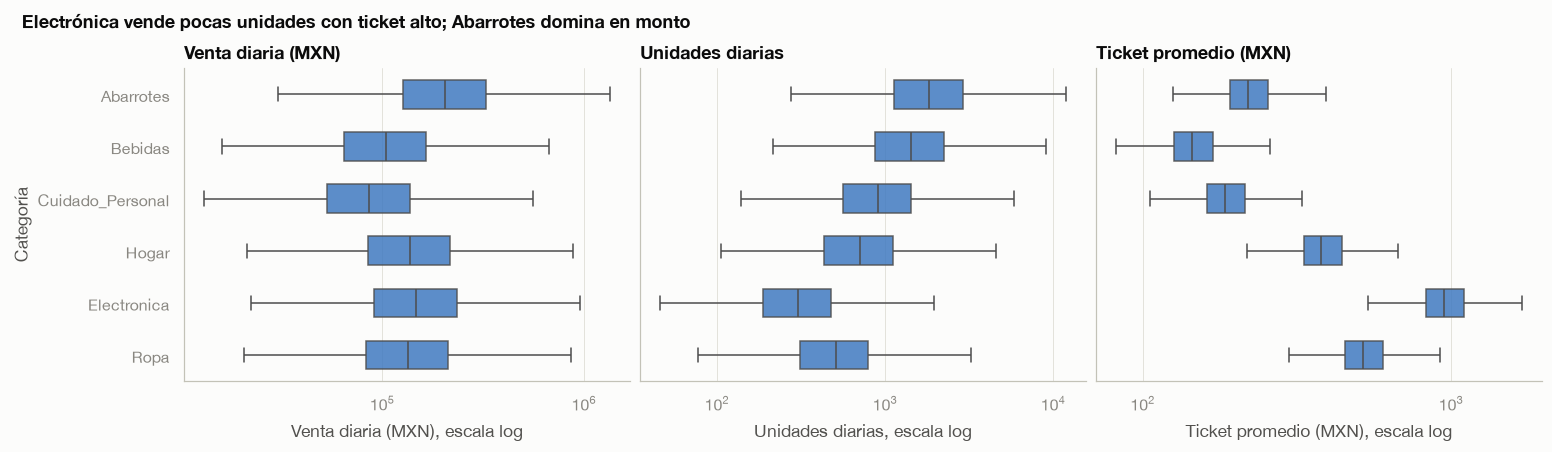

In [21]:
real = panel[~panel["is_missing_row"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True, layout="constrained")
metricas = [("amount_total", "Venta diaria (MXN)"), ("units_sold", "Unidades diarias"), ("avg_ticket", "Ticket promedio (MXN)")]
for ax, (col, titulo) in zip(axes, metricas):
    sns.boxplot(data=real, x=col, y="category", order=viz.CATEGORY_ORDER, color=viz.SERIES[0],
                log_scale=True, showfliers=False, width=0.55, ax=ax, boxprops={"alpha": 0.85})
    ax.set(title=titulo, xlabel=titulo + ", escala log", ylabel="Categoría" if col == "amount_total" else "")
fig.suptitle("Electrónica vende pocas unidades con ticket alto; Abarrotes domina en monto", x=0.01, ha="left", fontweight="bold")
plt.show()

In [22]:
real.groupby("category")[["amount_total", "units_sold", "avg_ticket", "transactions_clean"]].median().round(0).sort_values("amount_total", ascending=False)

,amount_total,units_sold,avg_ticket,transactions_clean
category,,,,
Abarrotes,"203,838.00","1,826.00",219.00,944.00
Electronica,"147,017.00",303.00,948.00,157.00
Hogar,"136,760.00",708.00,379.00,367.00
Ropa,"134,074.00",510.00,519.00,263.00
Bebidas,"104,335.00","1,416.00",145.00,734.00
Cuidado_Personal,"85,540.00",911.00,184.00,473.00


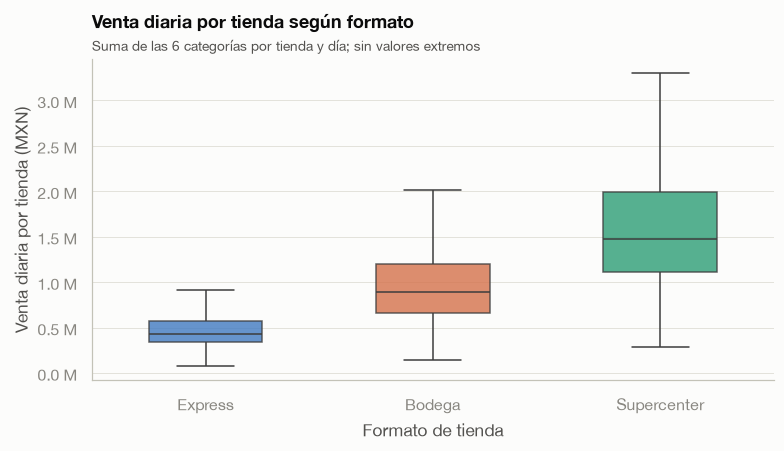

In [23]:
tienda_dia = real.groupby(["store_id", "date"], observed=True).agg(venta=("amount_total", "sum")).reset_index().merge(stores[["store_id", "store_format"]])
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=tienda_dia, x="store_format", y="venta", hue="store_format", order=viz.FORMAT_ORDER,
            palette=viz.FORMAT_COLORS, showfliers=False, width=0.5, legend=False, ax=ax, boxprops={"alpha": 0.8})
viz.fmt_millions(ax, decimals=1)
ax.set(xlabel="Formato de tienda", ylabel="Venta diaria por tienda (MXN)")
ax.set_title("Venta diaria por tienda según formato")
viz.subtitle(ax, "Suma de las 6 categorías por tienda y día; sin valores extremos")
plt.show()

Abarrotes es la categoría más grande en monto; Electrónica vende pocas unidades pero con ticket
alto. No hay valores negativos ni ceros en ninguna métrica.

## 8 · Patrones temporales

Venta total de la cadena por día, con los eventos del calendario:

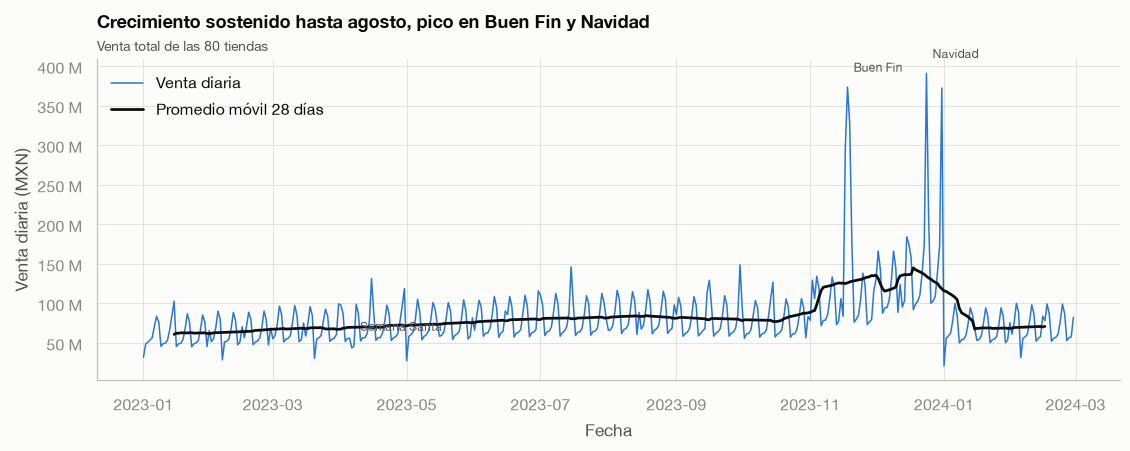

In [24]:
diaria = real.groupby("date")["amount_total"].sum()
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.lineplot(x=diaria.index, y=diaria.values, color=viz.SERIES[0], linewidth=1, ax=ax, label="Venta diaria")
sns.lineplot(x=diaria.index, y=diaria.rolling(28, center=True).mean().values, color=viz.INK, linewidth=1.8, ax=ax, label="Promedio móvil 28 días")
ax.set(xlabel="Fecha", ylabel="Venta diaria (MXN)")
for d, txt in [("2023-04-07", "Semana Santa"), ("2023-11-18", "Buen Fin"), ("2023-12-24", "Navidad")]:
    ax.annotate(txt, (pd.Timestamp(d), diaria.loc[d]), xytext=(4, 10), textcoords="offset points", fontsize=8, color=viz.INK_2)
viz.fmt_millions(ax)
ax.set_title("Crecimiento sostenido hasta agosto, pico en Buen Fin y Navidad")
viz.subtitle(ax, "Venta total de las 80 tiendas")
ax.legend(loc="upper left")
plt.show()

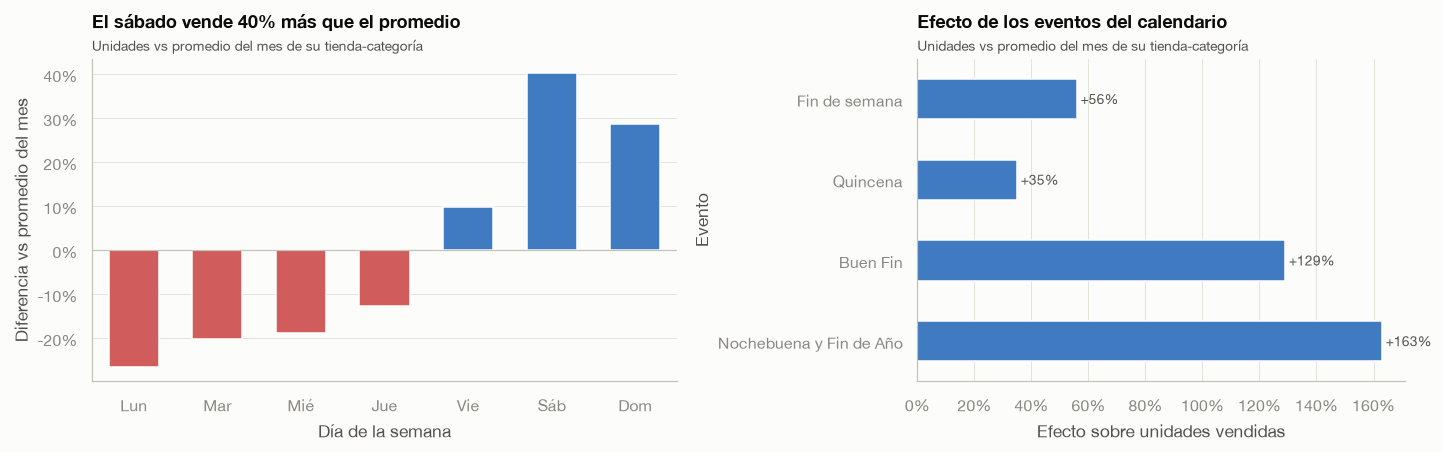

In [25]:
r = real.copy()
r["rel"] = r["units_sold"] / r.groupby(["store_id", "category", "year", "month"])["units_sold"].transform("mean")
dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
etiquetas = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
dow = r.groupby("day_name")["rel"].mean().reindex(dias)
efectos = pd.Series(
    {
        "Fin de semana": r.loc[r["is_weekend"], "rel"].mean() / r.loc[~r["is_weekend"], "rel"].mean() - 1,
        "Quincena": r.loc[r["is_payday"], "rel"].mean() / r.loc[~r["is_payday"], "rel"].mean() - 1,
        "Buen Fin": r.loc[r["is_buen_fin"], "rel"].mean() - 1,
        "Nochebuena y Fin de Año": r.loc[r["holiday_name"].isin(["Nochebuena", "Fin de Año"]), "rel"].mean() - 1,
    }
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.2, 1]}, layout="constrained")
dow_df = pd.DataFrame({"dia": etiquetas, "efecto": dow.values - 1})
dow_df["signo"] = np.where(dow_df["efecto"] >= 0, "arriba", "abajo")
sns.barplot(data=dow_df, x="dia", y="efecto", hue="signo", palette={"arriba": viz.DIVERGING["pos"], "abajo": viz.DIVERGING["neg"]}, width=0.6, legend=False, ax=a1)
a1.axhline(0, color=viz.AXIS, linewidth=0.8)
viz.fmt_pct(a1)
a1.set(xlabel="Día de la semana", ylabel="Diferencia vs promedio del mes")
a1.set_title("El sábado vende 40% más que el promedio")
viz.subtitle(a1, "Unidades vs promedio del mes de su tienda-categoría")
ef_df = efectos.rename("efecto").rename_axis("evento").reset_index()
sns.barplot(data=ef_df, y="evento", x="efecto", color=viz.SERIES[0], width=0.5, ax=a2)
for y, v in enumerate(ef_df["efecto"]):
    a2.text(v, y, f" {v:+.0%}", va="center", fontsize=9, color=viz.INK_2)
viz.fmt_pct(a2, axis="x")
a2.set(xlabel="Efecto sobre unidades vendidas", ylabel="Evento")
a2.set_title("Efecto de los eventos del calendario")
viz.subtitle(a2, "Unidades vs promedio del mes de su tienda-categoría")
plt.show()

In [26]:
# El efecto de los eventos grandes cambia por formato: dato clave para el pronóstico.
base_oct = real[real["month"] == 10].groupby(["store_id", "category"])["units_sold"].mean().rename("base")
ev = real.join(base_oct, on=["store_id", "category"])
ev["idx"] = ev["units_sold"] / ev["base"]
pd.DataFrame(
    {
        "Buen Fin vs octubre": ev[ev["is_buen_fin"]].groupby("store_format", observed=True)["idx"].mean() - 1,
        "Navidad (15 dic-6 ene) vs octubre": ev[ev["is_navidad_season"] & (ev["date"] < "2024-01-07")].groupby("store_format", observed=True)["idx"].mean() - 1,
    }
).style.format("{:+.0%}")

,Buen Fin vs octubre,Navidad (15 dic-6 ene) vs octubre
store_format,,
Express,+213%,+51%
Bodega,+289%,+48%
Supercenter,+282%,+70%


- **Fin de semana +56%**, sábado el día más fuerte y lunes el más débil.
- **Quincena +35%**: el día 15 y el último de cada mes.
- **Buen Fin: 3 a 4 veces** el nivel de octubre, y picos de 8 a 10 veces en Nochebuena y Fin de
  Año; caída fuerte el 1 de enero.
- **El efecto cambia por formato:** el Buen Fin pega menos en Express (+213% vs +289% en Bodega)
  y la temporada navideña sube más en Supercenter (+70% vs ~+50%).

> **Decisión.** Estos efectos son reales y grandes: son la materia prima del pronóstico
> (variables de calendario e interacción evento × formato). Los picos **no se tratan como
> outliers** (sección 12).

## 9 · Tiendas

¿Qué explica que una tienda venda más que otra? Regresión del log de la venta diaria promedio
de cada tienda contra sus atributos. Los coeficientes en log se leen como diferencia porcentual
aproximada.

**Cómo se calcula.** Se promedia la venta diaria de cada tienda (suma de sus 6 categorías) y se
ajusta una regresión lineal (OLS) del logaritmo de esa venta contra formato, región, nivel
socioeconómico y tamaño. Lo que la regresión no explica (el residuo) es el **desempeño propio de
la tienda**: `exp(residuo)` = venta real / venta esperada para una tienda con esos atributos.
Se repite lo mismo para unidades, para separar volumen de precio.

In [27]:
import statsmodels.formula.api as smf

# Venta y unidades diarias promedio por tienda (suma de las 6 categorías por día).
t = (
    real.groupby(["store_id", "date"]).agg(venta=("amount_total", "sum"), unidades=("units_sold", "sum"))
    .groupby("store_id").mean().reset_index().merge(stores, on="store_id")
)
t["log_venta"], t["log_unidades"], t["log_m2"] = np.log(t["venta"]), np.log(t["unidades"]), np.log(t["size_sqm"])
formula = "~ C(store_format, Treatment('Bodega')) + C(region, Treatment('Centro')) + C(socioeconomic_level, Treatment('C')) + log_m2"
m_venta = smf.ols("log_venta " + formula, data=t).fit()
m_unid = smf.ols("log_unidades " + formula, data=t).fit()
coef = pd.DataFrame({"venta (MXN)": m_venta.params, "unidades": m_unid.params, "p-valor venta": m_venta.pvalues}).drop("Intercept")
coef.index = coef.index.str.replace(r"C\((\w+), Treatment\('[^']+'\)\)\[T\.", "", regex=True).str.replace("]", "")
print(f"R² venta: {m_venta.rsquared:.2f} · R² unidades: {m_unid.rsquared:.2f}")
coef.style.format({"venta (MXN)": "{:+.2f}", "unidades": "{:+.2f}", "p-valor venta": "{:.3f}"})

R² venta: 0.89 · R² unidades: 0.88


,venta (MXN),unidades,p-valor venta
Express,-0.73,-0.72,0.000
Supercenter,+0.47,+0.47,0.000
Norte,+0.02,+0.02,0.754
Occidente,+0.01,+0.01,0.887
Oriente,-0.15,-0.15,0.036
Sur,-0.19,-0.19,0.022
C+,+0.13,-0.03,0.018
B,+0.36,+0.01,0.000
A/B,+0.48,-0.05,0.000
log_m2,+0.03,+0.03,0.666


Lectura (todo contra una Bodega del Centro, nivel C):

- El **formato** explica la mayor parte del volumen.
- El **nivel socioeconómico mueve la venta en pesos pero no las unidades**: las tiendas A/B
  venden las mismas unidades a mayor precio.
- **Oriente y Sur venden menos volumen** incluso comparados con tiendas equivalentes.
- **Más m² no vende más** dentro del mismo formato (coeficiente cercano a cero).

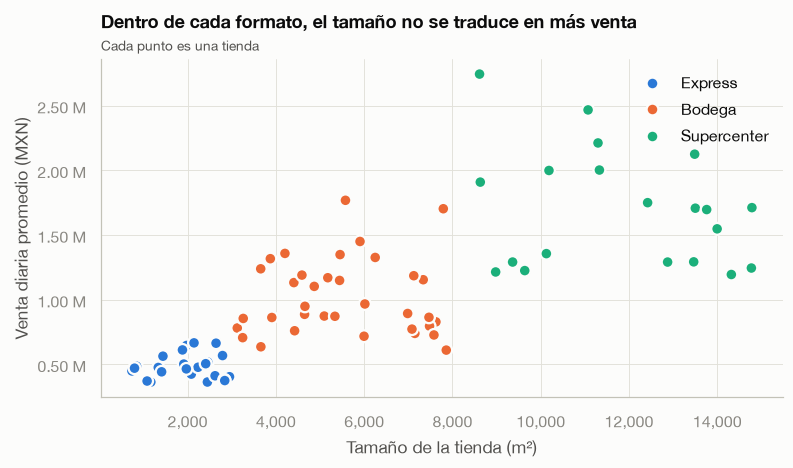

In [28]:
t["residuo"] = m_venta.resid
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=t, x="size_sqm", y="venta", hue="store_format", hue_order=viz.FORMAT_ORDER,
                palette=viz.FORMAT_COLORS, s=60, edgecolor=viz.SURFACE, linewidth=1.5, ax=ax)
viz.fmt_thousands(ax, axis="x")
viz.fmt_millions(ax, decimals=2)
ax.set(xlabel="Tamaño de la tienda (m²)", ylabel="Venta diaria promedio (MXN)")
ax.legend(title="")
ax.set_title("Dentro de cada formato, el tamaño no se traduce en más venta")
viz.subtitle(ax, "Cada punto es una tienda")
plt.show()

**¿Es estable o es ruido?** Se repite la regresión por separado con enero-julio y con
agosto-febrero, y se correlaciona el residuo de cada tienda entre ambos periodos. Si fuera
suerte, la correlación sería cercana a cero.

In [29]:
# ¿El desempeño de cada tienda frente a lo esperado es estable o es ruido?
corte = pd.Timestamp("2023-08-01")
def residuo_periodo(df):
    x = df.groupby(["store_id", "date"])["amount_total"].sum().groupby("store_id").mean().rename("venta").reset_index().merge(stores, on="store_id")
    x["log_venta"], x["log_m2"] = np.log(x["venta"]), np.log(x["size_sqm"])
    return smf.ols("log_venta " + formula, data=x).fit().resid.set_axis(x["store_id"])
r1, r2 = residuo_periodo(real[real["date"] < corte]), residuo_periodo(real[real["date"] >= corte])
print(f"Correlación del desempeño relativo ene-jul vs ago-feb: {r1.corr(r2):.3f}")
print(f"Tiendas >15% por debajo de lo esperado: {(np.exp(t['residuo']) < 0.85).sum()} · >15% por arriba: {(np.exp(t['residuo']) > 1.15).sum()}")

Correlación del desempeño relativo ene-jul vs ago-feb: 0.999
Tiendas >15% por debajo de lo esperado: 17 · >15% por arriba: 21


> **Decisión.** Los atributos explican ~90% de la diferencia entre tiendas, y lo que queda
> (±17%) es **una característica estable de cada tienda**: medido en dos periodos distintos da
> prácticamente lo mismo. Eso justifica el **análisis de potencial frente a pares**: hay tiendas
> que consistentemente venden menos que sus comparables.

## 10 · Categorías

Se probaron varias formas de interacción entre categorías. Primero, ¿cuánto de la variación de
las unidades diarias explica cada factor?

**Cómo se calcula.** Sobre el logaritmo de las unidades se quita, por pasos, el promedio de cada
grupo (primero categoría, luego tienda, fecha y sus combinaciones). Lo que cada paso quita,
dividido entre la varianza total, es la parte que explica ese factor. Si las categorías
interactuaran con las tiendas o con el tiempo, los renglones "tienda × categoría" y "fecha ×
categoría" serían grandes.

In [30]:
v = real.dropna(subset=["units_sold"]).copy()
resto = np.log(v["units_sold"]) - np.log(v["units_sold"]).mean()
total = resto.var()
partes = {}
for nombre, llaves in [("categoría", ["category"]), ("tienda", ["store_id"]), ("fecha", ["date"]),
                       ("tienda × categoría", ["store_id", "category"]), ("fecha × categoría", ["date", "category"]),
                       ("tienda × fecha", ["store_id", "date"])]:
    m = resto.groupby([v[k] for k in llaves]).transform("mean")
    partes[nombre] = m.var() / total
    resto = resto - m
partes["ruido diario"] = resto.var() / total
pd.Series(partes, name="% de la varianza").to_frame().style.format("{:.1%}")

,% de la varianza
categoría,43.9%
tienda,31.0%
fecha,15.2%
tienda × categoría,0.0%
fecha × categoría,0.1%
tienda × fecha,1.7%
ruido diario,8.1%


**Co-movimiento.** Se quita a cada categoría su nivel normal (tienda × mes × día de la semana) y
se correlaciona lo que sobra entre categorías del mismo día y tienda. Si dos categorías fueran
complementos, esa pareja se correlacionaría más que las demás; si fueran sustitutos, menos.

In [31]:
# Co-movimiento diario: residuo de cada categoría tras quitar su nivel tienda-mes-día de semana
v["e"] = np.log(v["units_sold"]) - np.log(v["units_sold"]).groupby([v["store_id"], v["category"], v["month"], v["year"], v["day_of_week"]]).transform("mean")
P = v.pivot_table(index=["store_id", "date"], columns="category", values="e")
corr = P.corr()
sin_comun = P.sub(P.mean(axis=1), axis=0).corr()
print("Correlación promedio entre pares de categorías:", round(corr.where(~np.eye(6, dtype=bool)).stack().mean(), 3))
print("Tras quitar el efecto común tienda-día (afluencia):", round(sin_comun.where(~np.eye(6, dtype=bool)).stack().mean(), 3), "(ruido puro con 6 categorías da −0.20)")

Correlación promedio entre pares de categorías: 0.254
Tras quitar el efecto común tienda-día (afluencia): -0.206 (ruido puro con 6 categorías da −0.20)


In [32]:
mezcla = real.groupby(["store_id", "category"])["amount_total"].sum().unstack()
mezcla = mezcla.div(mezcla.sum(axis=1), axis=0)
mezcla.describe().loc[["mean", "std", "min", "max"]].style.format("{:.1%}")

category,Abarrotes,Bebidas,Cuidado_Personal,Electronica,Hogar,Ropa
mean,25.1%,12.9%,10.6%,18.1%,16.9%,16.5%
std,0.2%,0.1%,0.1%,0.2%,0.1%,0.1%
min,24.6%,12.6%,10.3%,17.7%,16.5%,16.1%
max,25.7%,13.2%,10.8%,18.5%,17.2%,16.7%


| Interacción probada | Resultado |
|---|---|
| Tienda × categoría (¿alguna tienda es débil en una categoría?) | 0.02% de la varianza; la mezcla varía ±1% entre tiendas |
| Fecha × categoría (¿estacionalidad propia?) | 0.1% de la varianza; perfiles semanales y de eventos idénticos |
| Complementos o sustitutos día a día | Todas las parejas se correlacionan igual; sin el efecto común, queda ruido puro |

Las categorías se comportan como **la misma demanda con distinta escala**: se mueven juntas
con la afluencia de la tienda (el efecto común explica ~38% del ruido diario) y nada más.

> **Decisión.** No se construye un análisis de interacciones entre categorías: produciría ruido
> presentado como hallazgo. Lo que sí se aprovecha: **un solo modelo global** con la categoría
> como variable (no 6 modelos), un pronóstico **coherente entre niveles** (categoría → tienda →
> región) y, para inventarios, que el riesgo entre categorías **no se diversifica** porque se
> mueven juntas.

## 11 · Promociones

Las promociones están activas en ~20% de los días de cada tienda-categoría. La pregunta de
negocio es si **venden más en pesos**. Se compara el monto vendido en días con y sin promoción
**dentro de la misma tienda, categoría y mes**, lo que controla tamaño de tienda, categoría y
estacionalidad sin necesidad de un modelo.

Primero, ¿cómo se asignaron? Si la promoción se activara más en fines de semana o en ciertas
tiendas, la comparación estaría sesgada:

In [33]:
pr = real.copy()
pd.DataFrame(
    {
        "por formato": pr.groupby("store_format", observed=True)["has_promotion"].mean(),
    }
).T.style.format("{:.1%}")

store_format,Express,Bodega,Supercenter
por formato,20.0%,19.9%,20.1%


In [34]:
pd.DataFrame(
    {
        "fin de semana": pr.groupby("is_weekend")["has_promotion"].mean(),
        "quincena": pr.groupby("is_payday")["has_promotion"].mean(),
    }
).style.format("{:.1%}")

,fin de semana,quincena
False,19.9%,20.0%
True,20.1%,20.2%


**Cómo se calcula.** Para cada celda tienda × categoría × mes (6,712 celdas) se divide el monto
promedio de los días con promoción entre el de los días sin promoción, y se resta 1. El efecto
reportado es el promedio de las celdas. El intervalo de confianza sale de un **bootstrap**: se
remuestrean las celdas 2,000 veces y se toma el rango donde cae el 95% de los promedios.

In [35]:
pr["ym"] = pr["date"].dt.to_period("M")
celda = ["store_id", "category", "ym"]
resultados = {}
for col, nombre in [("amount_total", "Monto vendido (MXN)"), ("units_sold", "Unidades"),
                    ("transactions_clean", "Transacciones reales"), ("total_transactions_reported", "Transacciones reportadas (infladas)")]:
    lift = quality.within_cell_lift(pr.dropna(subset=[col]), col, "has_promotion", celda)
    media, lo, hi = quality.bootstrap_ci(lift)
    resultados[nombre] = {"efecto": media, "IC 95% inf": lo, "IC 95% sup": hi, "celdas": len(lift)}
efecto = pd.DataFrame(resultados).T
efecto.style.format({"efecto": "{:+.2%}", "IC 95% inf": "{:+.2%}", "IC 95% sup": "{:+.2%}", "celdas": "{:,.0f}"})

,efecto,IC 95% inf,IC 95% sup,celdas
Monto vendido (MXN),+0.62%,+0.17%,+1.08%,"6,712"
Unidades,+1.09%,+0.59%,+1.62%,"6,711"
Transacciones reales,+0.67%,+0.25%,+1.09%,"6,712"
Transacciones reportadas (infladas),+23.08%,+22.56%,+23.62%,"6,712"


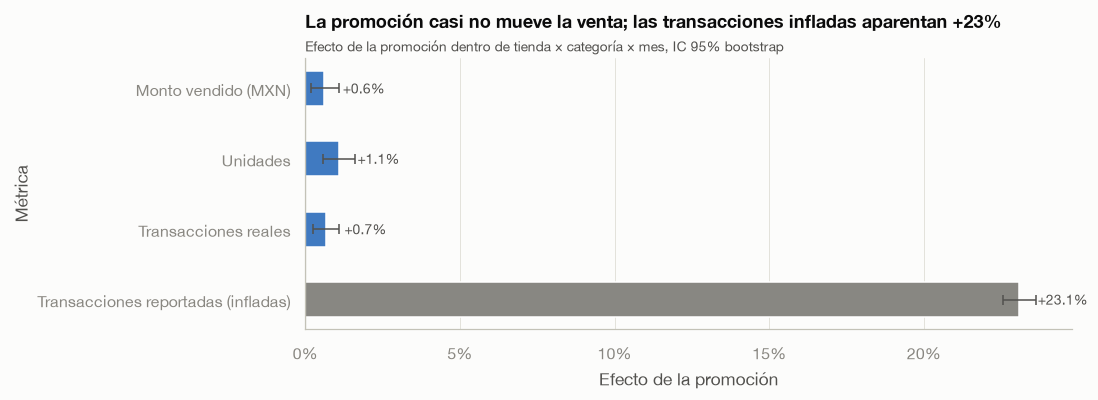

In [36]:
ef = efecto.rename_axis("metrica").reset_index()
ef["tipo"] = np.where(ef["metrica"].str.contains("infladas"), "dato inflado", "dato real")
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.barplot(data=ef, y="metrica", x="efecto", hue="tipo", palette={"dato real": viz.SERIES[0], "dato inflado": viz.MUTED},
            width=0.5, legend=False, ax=ax)
ax.errorbar(ef["efecto"], range(len(ef)), xerr=[ef["efecto"] - ef["IC 95% inf"], ef["IC 95% sup"] - ef["efecto"]],
            fmt="none", ecolor=viz.INK_2, elinewidth=1, capsize=3)
for y, v in enumerate(ef["efecto"]):
    ax.text(max(v, 0) + 0.006, y, f"{v:+.1%}", va="center", fontsize=9, color=viz.INK_2)
ax.axvline(0, color=viz.AXIS, linewidth=0.8)
viz.fmt_pct(ax, axis="x")
ax.set(xlabel="Efecto de la promoción", ylabel="Métrica")
ax.set_title("La promoción casi no mueve la venta; las transacciones infladas aparentan +23%")
viz.subtitle(ax, "Efecto de la promoción dentro de tienda × categoría × mes, IC 95% bootstrap")
plt.show()

- La promoción se asignó de forma **pareja** (~20%) entre formatos, fines de semana y
  quincenas: se comporta como un **experimento aleatorio**, lo que hace la comparación limpia.
- **El monto vendido apenas se mueve: +0.6%** (IC 95%: +0.2% a +1.1%). Las unidades suben ~1%,
  pero el precio por unidad baja ~1% en promoción, así que el descuento se come casi toda la
  venta adicional. Es estadísticamente distinto de cero, pero **irrelevante para el negocio**.
- **Advertencia de calidad de datos:** con `total_transactions` la promoción aparenta
  **+23% de transacciones**. Es el efecto de las transacciones infladas (sección 4), no venta
  real.

> **Siguiente paso (notebook de promociones).** Medir el efecto mínimo que podríamos detectar,
> el desglose por segmento y el costo en pesos de dar descuentos sin venta incremental.

## 12 · Picos y valores extremos

¿Hay outliers que limpiar? Se compara cada día contra la mediana de su tienda-categoría:

In [37]:
x = real.copy()
x["vs_mediana"] = quality.ratio_to_baseline(x["units_sold"], [x["store_id"], x["category"]])
extremos = x[(x["vs_mediana"] > 4) | (x["vs_mediana"] < 0.25)]
print(f"Días extremos (>4× o <0.25× la mediana): {len(extremos):,} de {len(x):,} ({len(extremos) / len(x):.2%})")
extremos.assign(evento=extremos["holiday_name"].fillna("sin evento")).groupby("evento").size().sort_values(ascending=False).head(10).rename("filas").to_frame()

Días extremos (>4× o <0.25× la mediana): 1,928 de 203,958 (0.95%)


,filas
evento,
Buen Fin,804
Fin de Año,360
Nochebuena,341
Año Nuevo,179
Día del Trabajo,66
Día de la Constitución,58
sin evento,46
Navidad,40
Natalicio Benito Juárez,25


In [38]:
sin_evento = extremos[~extremos["is_holiday"] & ~extremos["is_navidad_season"]]
print(f"Extremos fuera de festivos y temporada navideña: {len(sin_evento):,}")
if len(sin_evento):
    display(sin_evento[["date", "store_id", "category", "units_sold", "vs_mediana", "is_payday", "is_weekend"]].sort_values("vs_mediana").head())

Extremos fuera de festivos y temporada navideña: 14


,date,store_id,category,units_sold,vs_mediana,is_payday,is_weekend
202775,2023-02-20,STR_080,Electronica,38.00,0.20,False,False
61724,2023-04-10,STR_025,Bebidas,442.00,0.21,False,False
164115,2023-03-07,STR_065,Cuidado_Personal,120.00,0.21,False,False
139046,2023-03-13,STR_055,Electronica,78.00,0.23,False,False
126207,2024-02-12,STR_050,Cuidado_Personal,211.00,0.24,False,False


> **Decisión.** El 99% de los valores extremos caen en fechas de evento (Buen Fin, Fin de Año,
> Nochebuena, Año Nuevo); solo 14 de 1,928 ocurren en días normales. Son **demanda real**, justo la que más cuesta pronosticar
> mal. **No se eliminan ni se recortan**; el modelo debe aprender a anticiparlos.

## 13 · Conclusiones

### Top 5 hallazgos

**1. El sistema de reposición actual llega tarde y además usa información del futuro.**
Es un promedio de 7 días que incluye el día siguiente. Aun así, en Buen Fin y Nochebuena marca
apenas la mitad de la demanda real, y en los días posteriores marca entre 1.8 y 2.7 veces lo que
realmente se vendió (sección 5). En la operación
esto se traduce en anaqueles vacíos cuando más se vende y sobreinventario justo después.

**2. La demanda es muy predecible a partir del calendario.** Fin de semana +56%, quincena +35%,
Buen Fin 3 a 4 veces el nivel de octubre y picos de 8 a 10 veces en Nochebuena y Fin de Año. El
efecto cambia por formato de tienda (sección 8). Es exactamente la información que un pronóstico
puede anticipar y un promedio móvil no.

**3. Hay tiendas que venden consistentemente menos que sus comparables.** Formato, región y nivel
socioeconómico explican ~90% de la venta; lo que queda es estable en el tiempo (correlación
0.999 entre periodos). 17 tiendas venden más de 15% por debajo de lo esperado (sección 9).

**4. Las promociones casi no mueven la venta.** El monto sube +0.6%: las unidades suben ~1%
pero el descuento se come la diferencia. Con el campo `total_transactions` parecería un +23%,
pero ese campo viene inflado en días de promoción (secciones 4 y 11).

**5. Los datos son confiables una vez corregidos dos campos engañosos.** Los nulos son aleatorios
y casi todos se reconstruyen exactos. `replenishment_signal` y `total_transactions` quedan
excluidos como variables de modelo (secciones 3 a 6).

### Objetivo del análisis

A partir de estos hallazgos, el proyecto responde una pregunta principal y dos complementarias:

| | Pregunta de negocio | Hallazgos | Cómo se mide el éxito |
|---|---|---|---|
| **Principal** | ¿Podemos anticipar la demanda de la próxima semana por tienda y categoría mejor que el sistema actual, y cuánto vale eso en pesos? | 1, 2 | Error de pronóstico vs sistema actual en semanas no vistas; venta perdida y sobreinventario evitados en MXN |
| Complementaria | ¿Qué tiendas venden menos de lo que deberían y cuánto dinero hay en juego? | 3 | Brecha en MXN frente a pares (escenarios P50 y P75), por región |
| Complementaria | ¿Las promociones generan venta incremental? | 4 | Efecto en monto vendido con intervalo de confianza; costo del descuento en MXN |

### Decisiones de datos

| Tema | Decisión |
|---|---|
| Filas faltantes (42) | Se agregan marcadas, sin rellenar con ceros |
| Conteo de transacciones | `transactions_clean = efectivo + tarjeta` |
| `total_transactions` | Excluida como variable (inflada en promoción) |
| `replenishment_signal` | Excluida como variable (incluye t+1); se usa como referencia del sistema actual |
| Efectivo, monto en efectivo y ticket faltantes | Reconstruidos por identidad contable y marcados |
| `units_sold` faltante | No se imputa fuera del pipeline de entrenamiento |
| Picos de eventos | No son outliers; se modelan |

**Hipótesis descartadas con evidencia:** interacciones entre categorías, diferencias de mezcla por
tienda, efecto de la antigüedad de la tienda y diferencias en el uso de efectivo por nivel
socioeconómico.